# 데이터톤 3주차 - 첨부터 다시

### 0번 - 라이브러리 import 및 한글설정

Windows 한글 폰트(Malgun Gothic) 설정 완료


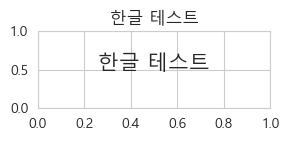

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import platform
from matplotlib import font_manager, rc

sns.set_style("whitegrid") 

# 한글 폰트 설정
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지


if platform.system() == 'Darwin':
    rc('font', family='AppleGothic')
    print(" Mac 한글 폰트(AppleGothic) 설정 완료")
    
elif platform.system() == 'Windows':
    font_path = "c:/Windows/Fonts/malgun.ttf"
    if os.path.exists(font_path):
        font_name = font_manager.FontProperties(fname=font_path).get_name()
        rc('font', family=font_name)
        print(f"Windows 한글 폰트({font_name}) 설정 완료")
    else:
        print("오류")


plt.figure(figsize=(3, 1))
plt.text(0.5, 0.5, '한글 테스트', ha='center', fontsize=15)
plt.title('한글 테스트')
plt.show()

## 1세대 분석

### [Step 1] 라이브러리 임포트 및 폰트 설정

[Step 2] 데이터 로드 및 중복 제거 함수

In [56]:
# 1. 파일 경로 설정 
base_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\1_gen'

# 키워드별 파일 매핑
files = {
    '합성의약품': 'dbpia_metadata_gen1_1.xlsx',
    'synthetic drug': 'dbpia_metadata_gen1_2.xlsx',
    '저분자 의약품': 'dbpia_metadata_gen1_3.xlsx',
    'small molecule drug': 'dbpia_metadata_gen1_4.xlsx'
}

# 2. 중복 제거 및 카운팅
def process_files(file_dict, base_dir):
    results = {} 

    print(f"{'키워드':<20} | {'원본':<6} | {'중복제거 후':<6} | {'삭제된 수':<6}")
    print("-" * 60)

    for keyword, filename in file_dict.items():
        full_path = os.path.join(base_dir, filename)
        
        if not os.path.exists(full_path):
            print(f" 파일 없음: {filename}")
            results[keyword] = 0
            continue
            
        try:
            # 엑셀 읽기
            df = pd.read_excel(full_path, engine='openpyxl')
            
            # 컬럼명 공백 제거
            df.columns = [str(c).strip() for c in df.columns]
            
            # 제목 컬럼 찾기 (논문제목, NODE_TTLE 등 자동 탐색)
            title_col = next((c for c in df.columns if c in ['논문제목', 'NODE_TTLE', 'Title', 'article_title']), None)
            
            if title_col:
                original_len = len(df)
                
                # 중복 제거 (제목 기준)
                df_clean = df.drop_duplicates(subset=[title_col])
                clean_len = len(df_clean)
                
                results[keyword] = clean_len # 결과 저장
                
                print(f"{keyword:<20} | {original_len:<8} | {clean_len:<10} | {original_len - clean_len:<8}")
            else:
                print(f" {keyword}: 제목 컬럼을 찾을 수 없습니다.")
                results[keyword] = 0
                
        except Exception as e:
            print(f" {keyword} 처리 중 오류: {e}")
            results[keyword] = 0
            
    return results

# 실행
keyword_counts = process_files(files, base_path)

키워드                  | 원본     | 중복제거 후 | 삭제된 수 
------------------------------------------------------------
합성의약품                | 708      | 707        | 1       
synthetic drug       | 833      | 828        | 5       
저분자 의약품              | 32       | 32         | 0       
small molecule drug  | 564      | 562        | 2       


## [Step 3] 막대그래프 시각화

C:\Users\jacob\AppData\Local\Temp\ipykernel_30676\3637036283.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x='Keyword', y='Count', data=df_plot, palette='viridis', edgecolor='black')


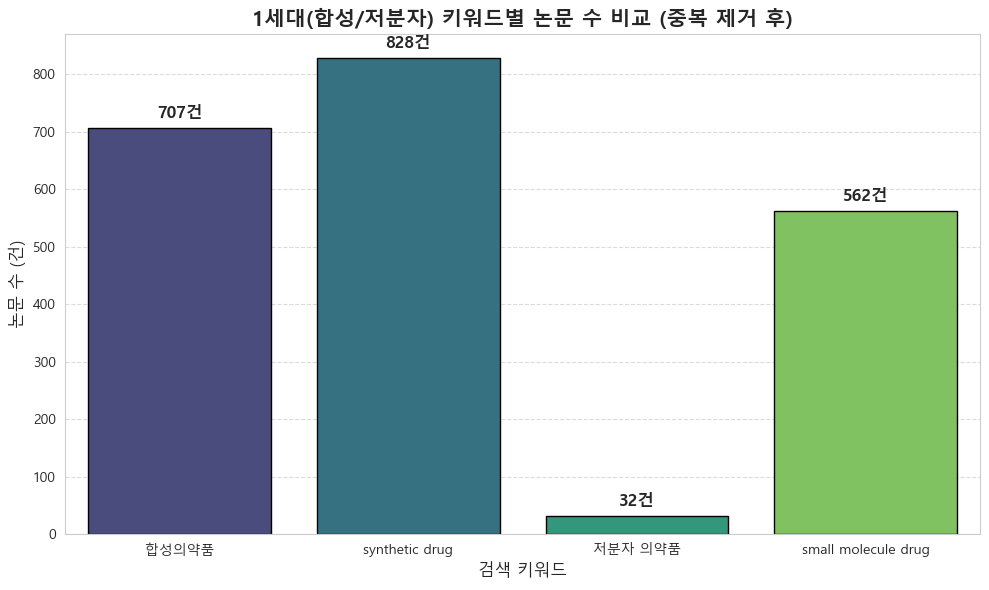

In [57]:
# 데이터프레임 변환
df_plot = pd.DataFrame(list(keyword_counts.items()), columns=['Keyword', 'Count'])

# 시각화
plt.figure(figsize=(10, 6))

# 막대그래프 그리기
bars = sns.barplot(x='Keyword', y='Count', data=df_plot, palette='viridis', edgecolor='black')

# 그래프 꾸미기
plt.title('1세대(합성/저분자) 키워드별 논문 수 비교 (중복 제거 후)', fontsize=15, fontweight='bold')
plt.xlabel('검색 키워드', fontsize=12)
plt.ylabel('논문 수 (건)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 막대 위에 숫자 표시
for p in bars.patches:
    height = p.get_height()
    plt.text(p.get_x() + p.get_width() / 2., height + 10, 
             f'{int(height)}건', ha = 'center', va = 'bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 2세대 분석

### [Step 1] 2세대 데이터 로드 및 중복 제거

In [58]:
# 파일 경로 설정
base_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\2_gen'

# 키워드별 파일 매핑
files_gen2 = {
    '항체 의약품': 'dbpia_metadata_gen2_1.xlsx',
    'antibody drug': 'dbpia_metadata_gen2_2.xlsx',
    '바이오의약품': 'dbpia_metadata_gen2_3.xlsx',
    'Biopharmaceuticals': 'dbpia_metadata_gen2_4.xlsx'
}

# 2. 중복 제거 , 카운팅 함수
def process_gen2_files(file_dict, base_dir):
    results = {} 

    print(f"{'키워드':<20} | {'원본':<6} | {'중복제거 후':<6} | {'삭제된 수':<6}")
    print("-" * 60)

    for keyword, filename in file_dict.items():
        full_path = os.path.join(base_dir, filename)
        
        if not os.path.exists(full_path):
            print(f"파일 없음: {filename} (경로를 확인해주세요)")
            results[keyword] = 0
            continue
            
        try:
            # 엑셀 읽기
            df = pd.read_excel(full_path, engine='openpyxl')
            
            # 컬럼명 공백 제거
            df.columns = [str(c).strip() for c in df.columns]
            
            # 제목 컬럼 찾기
            title_col = next((c for c in df.columns if c in ['논문제목', 'NODE_TTLE', 'Title', 'article_title']), None)
            
            if title_col:
                original_len = len(df)
                
                # 중복 제거 (제목 기준)
                df_clean = df.drop_duplicates(subset=[title_col])
                clean_len = len(df_clean)
                
                results[keyword] = clean_len 
                
                print(f"{keyword:<20} | {original_len:<8} | {clean_len:<10} | {original_len - clean_len:<8}")
            else:
                print(f" {keyword}: 제목 컬럼을 찾을 수 없습니다.")
                results[keyword] = 0
                
        except Exception as e:
            print(f" {keyword}  오류: {e}")
            results[keyword] = 0
            
    return results

# 실행
keyword_counts_gen2 = process_gen2_files(files_gen2, base_path)

키워드                  | 원본     | 중복제거 후 | 삭제된 수 
------------------------------------------------------------
항체 의약품               | 172      | 172        | 0       
antibody drug        | 849      | 848        | 1       
바이오의약품               | 565      | 563        | 2       
Biopharmaceuticals   | 288      | 287        | 1       


[Step 2] 막대그래프 시각화 (2세대)

C:\Users\jacob\AppData\Local\Temp\ipykernel_30676\440921678.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x='Keyword', y='Count', data=df_plot_gen2, palette='Blues_r', edgecolor='black')


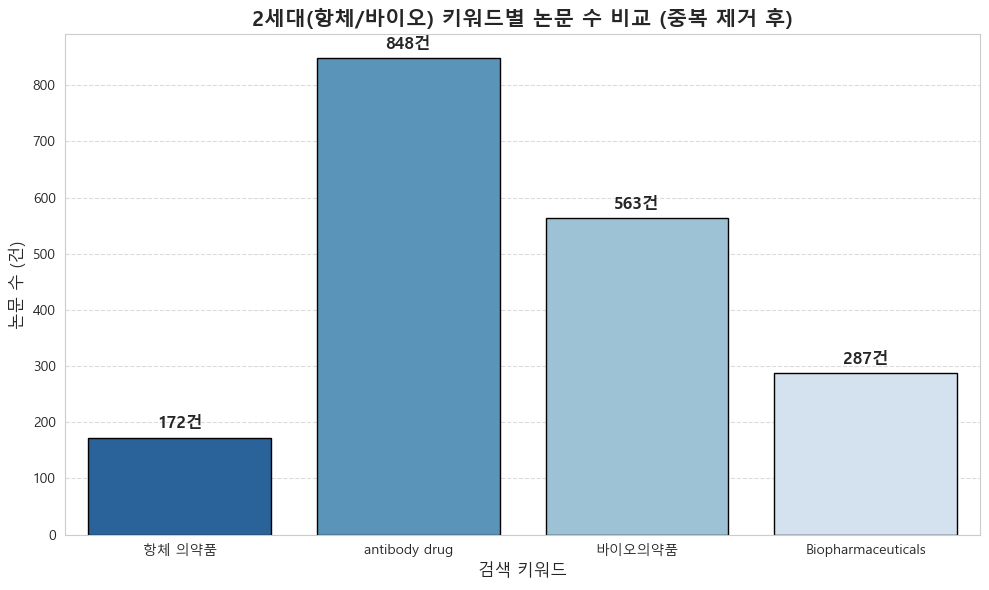

In [59]:
# 데이터프레임 변환
df_plot_gen2 = pd.DataFrame(list(keyword_counts_gen2.items()), columns=['Keyword', 'Count'])

# 시각화
plt.figure(figsize=(10, 6))

# 막대그래프 (색상: 파란색 계열 'Blues_r' 사용)
bars = sns.barplot(x='Keyword', y='Count', data=df_plot_gen2, palette='Blues_r', edgecolor='black')

# 그래프 꾸미기
plt.title('2세대(항체/바이오) 키워드별 논문 수 비교 (중복 제거 후)', fontsize=15, fontweight='bold')
plt.xlabel('검색 키워드', fontsize=12)
plt.ylabel('논문 수 (건)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 막대 위에 숫자 표시
for p in bars.patches:
    height = p.get_height()
    plt.text(p.get_x() + p.get_width() / 2., height + 10, 
             f'{int(height)}건', ha = 'center', va = 'bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 3세대 분석

### [Step 1] 3세대 데이터 로드 및 중복 제거

In [60]:
base_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\3_gen'

files_gen3 = {
    '디지털 치료제': 'dbpia_metadata_gen3_2.xlsx',
    'digital therapeutics': 'dbpia_metadata_gen3_3.xlsx',
    'mRNA 의약품': 'dbpia_metadata_gen3_4.xlsx',
    'mRNA drug': 'dbpia_metadata_gen3_5.xlsx',
    '첨단재생의료': 'dbpia_metadata_gen3_6.xlsx',
    'CRISPR Cas9': 'dbpia_metadata_gen3_7.xlsx',
    'CAR-T': 'dbpia_metadata_gen3_8.xlsx'
}

# 중복 제거 및 카운팅 함수
def process_gen3_files(file_dict, base_dir):
    results = {} 

    print(f"{'키워드':<25} | {'원본':<6} | {'중복제거 후':<6} | {'삭제된 수':<6}")
    print("-" * 65)

    for keyword, filename in file_dict.items():
        full_path = os.path.join(base_dir, filename)
        
        if not os.path.exists(full_path):
            print(f" 파일 없음: {filename} (경로 확인 필요)")
            results[keyword] = 0
            continue
            
        try:
            # 엑셀 읽기
            df = pd.read_excel(full_path, engine='openpyxl')
            # 컬럼명 공백 제거
            df.columns = [str(c).strip() for c in df.columns]
            
            # 제목 컬럼 찾기
            title_col = next((c for c in df.columns if c in ['논문제목', 'NODE_TTLE', 'Title', 'article_title']), None)
            
            if title_col:
                original_len = len(df)
                
                # 중복 제거 (제목 기준)
                df_clean = df.drop_duplicates(subset=[title_col])
                clean_len = len(df_clean)
                
                results[keyword] = clean_len 
                
                print(f"{keyword:<25} | {original_len:<8} | {clean_len:<10} | {original_len - clean_len:<8}")
            else:
                print(f" {keyword}: 제목 컬럼을 찾을 수 없습니다.")
                results[keyword] = 0
                
        except Exception as e:
            print(f" {keyword} 처리 중 오류: {e}")
            results[keyword] = 0
            
    return results

# 실행
keyword_counts_gen3 = process_gen3_files(files_gen3, base_path)

키워드                       | 원본     | 중복제거 후 | 삭제된 수 
-----------------------------------------------------------------
디지털 치료제                   | 75       | 75         | 0       
digital therapeutics      | 180      | 180        | 0       
mRNA 의약품                  | 113      | 113        | 0       
mRNA drug                 | 993      | 987        | 6       
첨단재생의료                    | 21       | 21         | 0       
CRISPR Cas9               | 806      | 802        | 4       
CAR-T                     | 43       | 43         | 0       


### [Step 2] 막대그래프 시각화 (3세대)

C:\Users\jacob\AppData\Local\Temp\ipykernel_30676\160090090.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x='Keyword', y='Count', data=df_plot_gen3, palette='Greens_r', edgecolor='black')


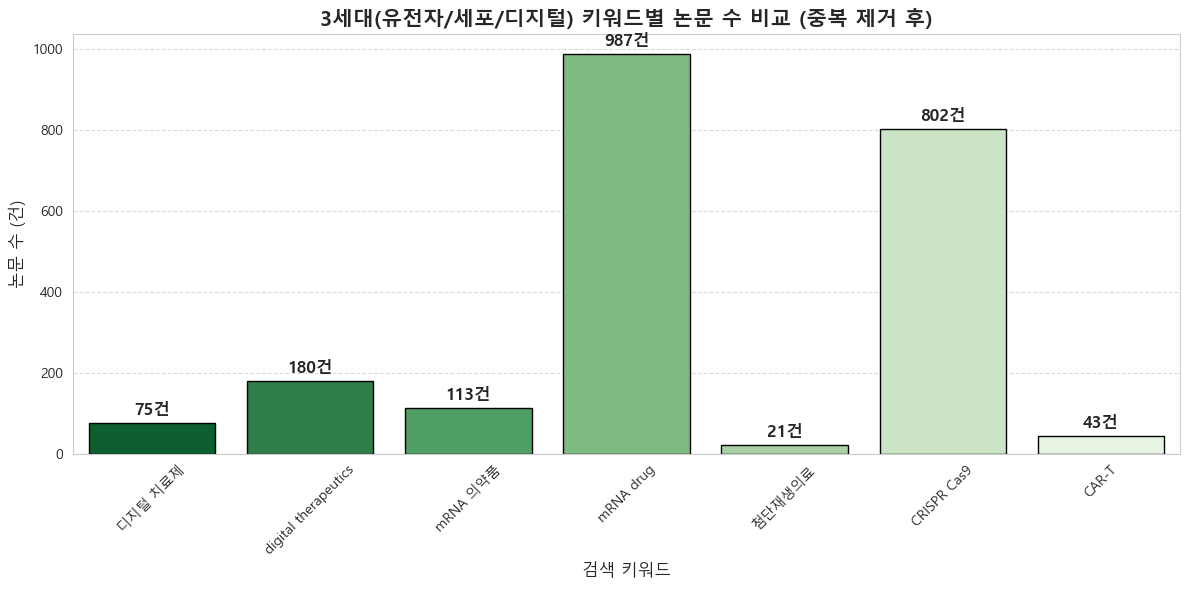

In [61]:
# 데이터프레임 변환
df_plot_gen3 = pd.DataFrame(list(keyword_counts_gen3.items()), columns=['Keyword', 'Count'])

# 시각화
plt.figure(figsize=(12, 6))

# 막대그래프
bars = sns.barplot(x='Keyword', y='Count', data=df_plot_gen3, palette='Greens_r', edgecolor='black')

# 그래프
plt.title('3세대(유전자/세포/디지털) 키워드별 논문 수 비교 (중복 제거 후)', fontsize=15, fontweight='bold')
plt.xlabel('검색 키워드', fontsize=12)
plt.ylabel('논문 수 (건)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45) # 키워드가 길어서 살짝 기울임

# 막대 위에 숫자 표시
for p in bars.patches:
    height = p.get_height()
    plt.text(p.get_x() + p.get_width() / 2., height + 10, 
             f'{int(height)}건', ha = 'center', va = 'bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 연도별 논문 수 비교

### [Step 1] 세대별 연도 데이터 추출 및 집계

In [62]:
base_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data'

file_paths = {
    '1세대': os.path.join(base_path, '1_gen', 'dbpia_metadata_gen1_total.xlsx'),
    '2세대': os.path.join(base_path, '2_gen', 'dbpia_metadata_gen2_total.xlsx'),
    '3세대': os.path.join(base_path, '3_gen', 'dbpia_metadata_gen3_total2.xlsx') 
}

def get_counts(filepath):

    try:
        # 엑셀 읽기
        df = pd.read_excel(filepath, engine='openpyxl')
        df.columns = [str(c).strip() for c in df.columns] # 컬럼 공백 제거
        
        # 필수 컬럼 찾기
        t_col = next((c for c in df.columns if c in ['논문제목','NODE_TTLE','Title']), None)
        y_col = next((c for c in df.columns if c in ['발행연월','발행년도','발행연도','Year']), None)
        
        if t_col and y_col:
            # 중복 제거 (제목 기준)
            df = df.drop_duplicates(subset=[t_col]) 
            
            # 연도 추출 (앞 4자리)
            df['Year'] = pd.to_numeric(df[y_col].astype(str).str[:4], errors='coerce')
            df = df.dropna(subset=['Year'])
            df['Year'] = df['Year'].astype(int)
            
            # 2010~2024년 필터링
            df = df[(df['Year'] >= 2010) & (df['Year'] <= 2024)]
            
            return df['Year'].value_counts().sort_index()
        else:
            print(f" 컬럼 부족: {filepath}")
            return None
    except Exception as e:
        print(f" 에러 : {e}")
        return None


s1 = get_counts(file_paths['1세대'])
s2 = get_counts(file_paths['2세대'])
s3 = get_counts(file_paths['3세대'])

# 하나의 데이터프레임으로 합치기
df_chart = pd.DataFrame({
    '1세대 (합성/저분자)': s1,
    '2세대 (항체/바이오)': s2,
    '3세대 (유전자/세포/디지털)': s3
}).fillna(0)
 # 결측치는 0으로 채움

print(df_chart)

      1세대 (합성/저분자)  2세대 (항체/바이오)  3세대 (유전자/세포/디지털)
Year                                              
2010           0.0             2               0.0
2011           0.0             3               0.0
2013         129.0           108              82.0
2014         133.0            79              99.0
2015         145.0            75             111.0
2016         157.0            91             106.0
2017         163.0           120             150.0
2018         146.0           108             150.0
2019         175.0           134             185.0
2020         172.0           146             184.0
2021         162.0           164             221.0
2022         134.0           131             169.0
2023         169.0           186             299.0
2024         145.0           155             247.0


### [Step 2] 꺾은선 그래프 시각화

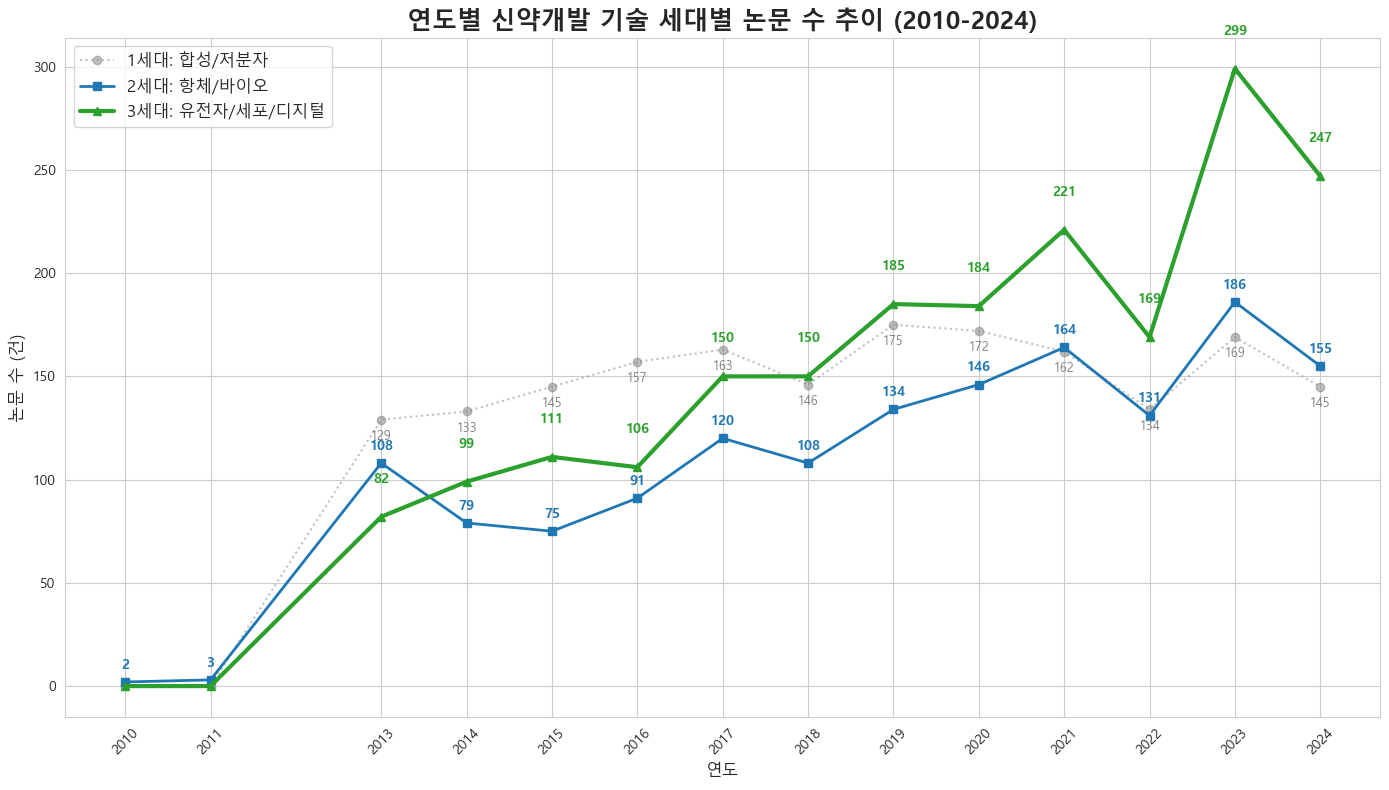

In [63]:
if not df_chart.empty:
    plt.figure(figsize=(14, 8)) # 그래프 크기 설정
    # sns.set_style("whitegrid") # 배경 스타일 -> 이거 때문에 한글깨짐

    # 그래프 만들기
    # 1세대 (회색 점선)
    plt.plot(df_chart.index, df_chart['1세대 (합성/저분자)'], 
             color='gray', marker='o', linestyle=':', alpha=0.5, label='1세대: 합성/저분자')
    
    # 2세대 (파란색 실선)
    plt.plot(df_chart.index, df_chart['2세대 (항체/바이오)'], 
             color='#1f77b4', marker='s', linewidth=2, label='2세대: 항체/바이오')
    
    # 3세대 (초록색 실선)
    plt.plot(df_chart.index, df_chart['3세대 (유전자/세포/디지털)'], 
             color='#2ca02c', marker='^', linewidth=3, label='3세대: 유전자/세포/디지털')





    # 숫자 표사
    for year in df_chart.index:
        # 1세대
        val1 = df_chart.loc[year, '1세대 (합성/저분자)']
        if val1 > 0:
            plt.text(year, val1 - 5, f'{int(val1)}', ha='center', va='top', fontsize=9, color='gray')

        # 2세대
        val2 = df_chart.loc[year, '2세대 (항체/바이오)']
        if val2 > 0:
            plt.text(year, val2 + 5, f'{int(val2)}', ha='center', va='bottom', fontsize=10, color='#1f77b4', fontweight='bold')

        # 3세대
        val3 = df_chart.loc[year, '3세대 (유전자/세포/디지털)']
        if val3 > 0:
            plt.text(year, val3 + 15, f'{int(val3)}', ha='center', va='bottom', fontsize=10, color='#2ca02c', fontweight='bold')

    # --- 그래프 ---
    plt.title('연도별 신약개발 기술 세대별 논문 수 추이 (2010-2024)', fontsize=18, fontweight='bold')
    plt.xlabel('연도', fontsize=12)
    plt.ylabel('논문 수 (건)', fontsize=12)
    plt.legend(fontsize=12, loc='upper left')
    
    # X축 눈금 (모든 연도 표시)
    plt.xticks(df_chart.index, rotation=45)
    
    plt.tight_layout()
    plt.show()
else:
    print(" 실패")

# -----------------------------------------------------------------------

## 논문 수와 주가(Stock Price) 비교 시각화

In [64]:
!pip install yfinance

# ----------------------------------------------------------------------------------------------------------------------------

### 제공받은 데이터에서 생명공학분야 논문만 추출

In [65]:
!pip install openpyxl

In [66]:
import pandas as pd
import json
import os

input_file = r'C:\Users\jacob\Desktop\ssu_Datathon\SSU_Datathon2025.json' 
output_file = 'society_rank_list.xlsx'

def load_json_safe(path):
    print(f" JSON 파일 로드 중... ({path})")
    
    if not os.path.exists(path):
        print(" 파일이 없습니다. 경로를 확인해주세요.")
        return pd.DataFrame()

    try:
        # 인코딩 자동 감지 시도
        try:
            with open(path, 'r', encoding='utf-8') as f:
                data = json.load(f)
        except:
            with open(path, 'r', encoding='cp949') as f: # 윈도우 한글
                data = json.load(f)
    except Exception as e:
        # 줄 단위 JSON 시도
        try:
            return pd.read_json(path, lines=True)
        except:
            print(f" 파일 읽기 실패: {e}")
            return pd.DataFrame()

    # 데이터가 딕셔너리에 포장된 경우 list 찾기
    if isinstance(data, dict):
        keys_to_check = ['data', 'items', 'response', 'body', 'result', 'records']
        
        found = False
        # 1차 탐색
        for key in keys_to_check:
            if key in data:
                data = data[key]
                if isinstance(data, list):
                    found = True
                    break
                # 2차 탐색 (중첩)
                if isinstance(data, dict):
                    for sub_key in keys_to_check:
                        if sub_key in data:
                            data = data[sub_key]
                            found = True
                            break
                if found: break
        
        if not found:
            # 리스트인 값을 강제로 찾음
            for k, v in data.items():
                if isinstance(v, list):
                    data = v
                    break

    if isinstance(data, list):
        return pd.DataFrame(data)
    else:
        print(" 데이터 리스트를 찾지 못함")
        return pd.DataFrame()

df = load_json_safe(input_file)

if not df.empty:
    print(f" 데이터 로드 완료,  총 {len(df)}건")
    
    # 컬럼명 대문자로 통일
    df.columns = [str(c).upper().strip() for c in df.columns]

    # 발행기관명(IPRD_NM) 컬럼 찾기
    if 'IPRD_NM' in df.columns:
        
        # 빈 값 제외하고 카운트
        society_counts = df['IPRD_NM'].fillna('미상').value_counts().reset_index()
        society_counts.columns = ['발행기관명(학회)', '논문 수']
        
        # 엑셀 저장
        society_counts.to_excel(output_file, index=False)
        print(f" 저장 -> {output_file}")
        
        # 상위 50개 출력
        print("\n[상위 50개 발행기관]")
        print("-" * 40)
        pd.set_option('display.max_rows', 50)
        print(society_counts.head(50))
        print("-" * 40)
        
    else:
        print(list(df.columns))
else:
    print("데이터를 로딩 실패.")

 JSON 파일 로드 중... (C:\Users\jacob\Desktop\ssu_Datathon\SSU_Datathon2025.json)
 데이터 로드 완료,  총 62199건
 저장 -> society_rank_list.xlsx

[상위 50개 발행기관]
----------------------------------------
                                                   발행기관명(학회)  논문 수
0                                                   한국산학기술학회  4863
1   Korean Institute of Information Scientists and Engineers  2141
2                                                     대한전기학회  2131
3                                                     대한기계학회  2119
4                                                    대한전자공학회  2055
5                                                   국제인공지능학회  1976
6                                                     한국통신학회  1866
7                                                     대한건축학회  1772
8                                                 한국디지털콘텐츠학회  1546
9                                                  한국컴퓨터정보학회  1498
10                                                    대한토목학회  1473
11         

## 너무 많아 다른애들 논문이(건축, 전기 등 연관 x 논문이 많이 뽑힘)

### 음... 제공받은 데이터로 트렌드 봤을때 왜인지 모르지만 3세대 감소... 근데 이정도는 그냥 데이터 수가 적어서 그런듯

학회만 뽑아내고 그안에서 키워드로 세대 분리해서 그리프 그려봤는데 그냥 데이터 수가 적어서 이상한 결과가 나옴



[Step 3] 미래 인재 이동 경로 및 융합 패턴 분석 코드
이 코드는 SSU_Final_Society_Cleaned.xlsx 파일을 사용하여 다음을 수행합니다.

Core Journal: 3세대 연구가 가장 활발한 학회(발행기관) 랭킹.

Key Players: 3세대 분야를 주도하는 상위 연구자(저자) 추출.

Convergence: 3세대 기술이 AI / 나노 / 공정 기술과 얼마나 융합되고 있는지 패턴 분석.

-> 이거도 의미 없는게 그냥 너무 데이터가 적음 

In [67]:
import pandas as pd
import json
import re
import os

input_file = r'C:\Users\jacob\Desktop\ssu_Datathon\SSU_Datathon2025.json' 
output_file = 'SSU_Final_Real_Targets.xlsx'


# (1) 학회 블랙리스트 (시스템, 정보, 재료 살림)
black_society_keywords = [
    '건축', '토목', '부동산', '교육', '경영', '경제', '행정', '사회', '인문', '어학', 
    '디자인', '예술', '체육', '미디어', '방송', '교통', '항행', '관광',
    '국방', '군사', '철도', '조선', '자동차', '발전소', '전력', '플랜트'
]

# (2) 노이즈 제거 (재료/식품/에너지 관련 내용 삭제)
exclude_keywords = [
    '연료전지', 'fuel cell', 'battery', '배터리', 'solar', '태양전지', 'display', '디스플레이',
    '섬유', 'fiber', 'film', '필름', 'coating', '코팅', 'adhesion', '접착', 
    'concrete', 'cement', 'waste', '폐기물', 'water treatment', '수처리',
    'food', '식품', 'extract', '추출물', 'fermentation', '발효', 'cosmetic', '화장품', '미백', '주름'
]

# (3) 핵심 키워드 (3세대 + 기술 + 의학)
gen3_keywords = ['유전자', '세포', '줄기세포', '크리스퍼', '카티', 'mrna', 'gene', 'cell', 'crispr', 'cas9', 'car-t']
tech_keywords = ['전달', '운반', '나노', '입자', 'delivery', 'carrier', 'nano', 'particle', 'dds', 'encapsulation', 'liposome']
medical_keywords = ['치료', '약물', '의약', 'therapy', 'drug', 'medicine'] # 의학적 맥락 필수


def run_full_pipeline(path):
    print(f" [통합 실행] 데이터 로드 및 분석 ({path})")
    
    # 1. 데이터 로드
    try:
        try:
            with open(path, 'r', encoding='utf-8') as f: data = json.load(f)
        except:
            with open(path, 'r', encoding='cp949') as f: data = json.load(f)
    except Exception as e:
        print(f" 파일 로드 실패: {e}"); return

    if isinstance(data, dict):
        for k in ['NODE_LIST', 'data', 'items']:
            if k in data: data = data[k]; break
            
    df = pd.DataFrame(data)
    df.columns = [str(c).upper().strip() for c in df.columns]
    
    # 텍스트 통합
    cols = ['NODE_TTLE', 'NODE_TTLE_EN', 'KR_ABST', 'EN_ABST', 'KYWD']
    target_cols = [c for c in cols if c in df.columns]
    df['FULL_TEXT'] = df[target_cols].fillna('').apply(lambda x: ' '.join(x.astype(str)), axis=1).str.lower()
    
    print(f" 원본 데이터: {len(df)}건")

    # 2. 필터링 로직
    # (1) 학회 필터링
    def is_clean_society(name):
        name = str(name)
        for bad in black_society_keywords:
            if bad in name: return False
        return True
    
    df = df[df['IPRD_NM'].fillna('').apply(is_clean_society)].copy()
    
    # (2) 노이즈 제거 (재료/식품 등)
    mask_noise = df['FULL_TEXT'].apply(lambda x: any(n in x for n in exclude_keywords))
    df_clean = df[~mask_noise].copy()
    
    # (3) [교집합] 3세대 + 기술 + 의학
    mask_gen3 = df_clean['FULL_TEXT'].apply(lambda x: any(k in x for k in gen3_keywords))
    mask_tech = df_clean['FULL_TEXT'].apply(lambda x: any(k in x for k in tech_keywords))
    mask_med = df_clean['FULL_TEXT'].apply(lambda x: any(k in x for k in medical_keywords))

    final_df = df_clean[mask_gen3 & mask_tech & mask_med].copy()

    print(f" [최종] 3세대 유전자 + 약물전달(DDS) 논문: {len(final_df)}건")

    # 3. 저장 및 결과 출력
    if len(final_df) > 0:
        # 엑셀 저장 (특수문자 제거)
        def clean_char(text):
            if isinstance(text, str): return re.sub(r'[\000-\010]|[\013-\014]|[\016-\037]', '', text)
            return text
        
        for col in final_df.select_dtypes(include=['object']).columns:
            final_df[col] = final_df[col].apply(clean_char)
            
        final_df.to_excel(output_file, index=False)
        print(f" 엑셀 저장: {output_file}")
        
        print("-" * 50)
        print(" [Top 10 검색 결과 리스트]")
        
        # 화면 출력용 설정
        pd.set_option('display.max_rows', None)
        pd.set_option('display.max_colwidth', None)
        
        # 주요 컬럼만 선택해서 보여주기
        cols_to_show = ['NODE_TTLE', 'AUTR_NM', 'IPRD_NM']
        display_cols = [c for c in cols_to_show if c in final_df.columns]
        
        display_df = final_df[display_cols].head(10).copy()
        display_df.index = range(1, len(display_df) + 1)
        
        # 주피터 노트북 출력
        try:
            from IPython.display import display
            display(display_df)
        except:
            print(display_df)
            
    else:
        print("조건에 맞는 논문이 0건입니다. 노이즈 키워드를 조금 줄여보세요.")

# 함수 실행
run_full_pipeline(input_file)

 [통합 실행] 데이터 로드 및 분석 (C:\Users\jacob\Desktop\ssu_Datathon\SSU_Datathon2025.json)
 원본 데이터: 62199건
 [최종] 3세대 유전자 + 약물전달(DDS) 논문: 8건
 엑셀 저장: SSU_Final_Real_Targets.xlsx
--------------------------------------------------
 [Top 10 검색 결과 리스트]


,NODE_TTLE,AUTR_NM,IPRD_NM
1,경구투여 약물전달 시스템을 위한 pH 반응성 칼슘-알긴산/PEO 하이드로젤 미세입자 합성,"정주언, 송유진, 강성민",한국고분자학회
2,"한양대학교 생명공학과 세포 및 나노치료제 공학 연구실(CNEL, Cell and Nanotherapy Engineering Lab)",박희호,한국생물공학회
3,교모세포종 진단 및 치료를 위한 바이오 드론 플랫폼: 현재 및 미래 전망,"이훈재, 김현욱",한국생물공학회
4,PubMed 초록 데이터 기반 BERTopic과 대규모 언어모델을 활용한 약물전달시스템 연구동향 분석,"최혁준, 강주영, 이한솔",한국지능정보시스템학회
5,Antimetabolite Prodrug Delivery for Non-small Cell Lung Cancer,"Ruda Lee, Sho Tanigawa, Yong Il Park, Hoon Kim",한국생물공학회
6,뇌 내 약물전달 시스템 개발을 위한 혈액 - 뇌 장벽 세포모델,"최정원, 박태은",한국고분자학회
7,Poly(azomethine) Based Micelles for Delivery of Caffeic Acid Phenethyl Ester,"Nermin Saliha Topuzogullari, Fatma Sayan Poyraz, Murat Topuzogullari, Banu Mansuroglu",한국고분자학회
8,Ultrasonic Targeting of NK Cell in Vessel Bifurcation for Immunotherapy: Simulation and Experimental Validation,"Saqib Sharif, 송형우, 정대원, Hiep Xuan Cao, 박종오, 강병전, 최은표",한국센서학회


In [68]:
import pandas as pd
import json
import os

# 파일 경로
input_file = r'C:\Users\jacob\Desktop\ssu_Datathon\SSU_Datathon2025.json' 

def raw_data_check(path):
    try:
        with open(path, 'r', encoding='utf-8') as f: data = json.load(f)
    except:
        with open(path, 'r', encoding='cp949') as f: data = json.load(f)

    if isinstance(data, dict):
        for k in ['NODE_LIST', 'data', 'items']:
            if k in data: data = data[k]; break
            
    df = pd.DataFrame(data)
    
    # 컬럼명 정리 및 텍스트 통합
    df.columns = [str(c).upper().strip() for c in df.columns]
    target_cols = [c for c in ['NODE_TTLE', 'KR_ABST', 'KYWD'] if c in df.columns]
    df['SEARCH_TEXT'] = df[target_cols].fillna('').apply(lambda x: ' '.join(x.astype(str)), axis=1).str.lower()
    
    print(f" 전체 데이터: {len(df)}건")
    print("-" * 60)

    mask_gene = df['SEARCH_TEXT'].str.contains('유전자|gene|crispr|카티|car-t', case=False, na=False)
    df_gene = df[mask_gene]
    
    print(f" '유전자/Gene' 키워드 포함 논문: {len(df_gene)}건")
    if len(df_gene) > 0:
        print("[샘플 10개]")
        for t in df_gene['NODE_TTLE'].head(10):
            print(f"- {t}")
    print("-" * 60)

    mask_cell = df['SEARCH_TEXT'].str.contains('세포치료|cell therapy|줄기세포|stem cell', case=False, na=False)
    df_cell = df[mask_cell]
    
    print(f" '세포치료/Stem Cell' 키워드 포함 논문: {len(df_cell)}건")
    if len(df_cell) > 0:
        print("[샘플 10개]")
        for t in df_cell['NODE_TTLE'].head(10):
            print(f"- {t}")
    print("-" * 60)

    mask_dds = df['SEARCH_TEXT'].str.contains('약물전달|drug delivery|dds|리포좀|liposome', case=False, na=False)
    df_dds = df[mask_dds]
    
    print(f" '약물전달/DDS' 키워드 포함 논문: {len(df_dds)}건")
    if len(df_dds) > 0:
        print("[샘플 10개]")
        for t in df_dds['NODE_TTLE'].head(10):
            print(f"- {t}")

    df_total = pd.concat([df_gene, df_cell, df_dds]).drop_duplicates()
    
    if len(df_total) > 0:
        df_total[['NODE_TTLE', 'IPRD_NM', 'AUTR_NM']].to_excel('SSU_Raw_Check.xlsx', index=False)
    else:
        print("오류")

raw_data_check(input_file)

 전체 데이터: 62199건
------------------------------------------------------------
 '유전자/Gene' 키워드 포함 논문: 2169건
[샘플 10개]
- 고침투율의 분산전원이 배전계통 보호 시스템에 미치는 영향을 고려한 과전류 계전기 정정값 최적화에 관한 연구
- 재생 태양광모듈의 고장 시점별 발전량 예측을 위한 재생 보정계수에 관한 연구
- 10 kW급 조력발전장치 개발 - 관수로 현장실험을 중심으로
- 기존 방조제에 설치 가능한 조력발전 장치 개발 - 개수로 현장실험 검증
- 메타버스 기반 실감 교육용 플랫폼 개발
- 중심이 개방된 와류기와 90도 파이프 엘보가 결합된 유동의 RANS 해석
- Performance Improvement of Fuzzy C-Means Clustering Algorithm by Optimized Early Stopping for Inhomogeneous Datasets
- 초·중등 수업에서 생성형 AI 활용을 위한 콘텐츠 개발 연구
- Research on Sensor Functionality of Next-generation Intelligent Semiconductor Devices using Ga₂O₃-based UV-C Detector Under Commercial Conditions
- 토픽모델링을 활용한 도시재생정책 이슈 분석 : 국토교통부 보도자료를 중심으로
------------------------------------------------------------
 '세포치료/Stem Cell' 키워드 포함 논문: 13건
[샘플 10개]
- 동종 조혈모세포 이식에서 생착 및 재발 판정을 위한 STR marker 검사의 유용성
- 3차원 나노/마이크로 구조를 활용한 줄기세포 분화 응용기술
- Polyampholyte의 닭 정원줄기세포 동결보존 효과
- 만능줄기세포 기반 신장 오가노이드의 연구 동향
- 오가노이드 기반 조직재생 치료제: 줄기세포와 조직공학 기술의

In [69]:
import pandas as pd
import json
import os


input_file = r'C:\Users\jacob\Desktop\ssu_Datathon\SSU_Datathon2025.json'

def check_pivot_strategy(path):
    print(f" 관점 전환(Pivot) 분석 ({path})")
    
    # 데이터 로드
    try:
        try:
            with open(path, 'r', encoding='utf-8') as f: data = json.load(f)
        except:
            with open(path, 'r', encoding='cp949') as f: data = json.load(f)
    except Exception as e:
        print(f" 파일 로드 실패: {e}"); return

    if isinstance(data, dict):
        for k in ['NODE_LIST', 'data', 'items']:
            if k in data: data = data[k]; break
            
    df = pd.DataFrame(data)
    df.columns = [str(c).upper().strip() for c in df.columns]
    
    # 텍스트 통합 (제목 + 초록 + 키워드)
    cols = ['NODE_TTLE', 'NODE_TTLE_EN', 'KR_ABST', 'EN_ABST', 'KYWD']
    target_cols = [c for c in cols if c in df.columns]
    df['FULL_TEXT'] = df[target_cols].fillna('').apply(lambda x: ' '.join(x.astype(str)), axis=1).str.lower()
    
    print(f" 전체 데이터: {len(df)}건")
    print("-" * 60)


    what_keywords = ['신약', 'new drug', 'novel drug', '임상', 'clinical trial']
    
    mask_what = df['FULL_TEXT'].apply(lambda x: any(k in x for k in what_keywords))
    df_what = df[mask_what]
    
    print(f" [Before] '신약/임상(What)' 키워드 검색 결과: {len(df_what)}건")
    print("   (대부분 공학 데이터와 관련 없는 단순 언급일 가능성 높음)")
    print("-" * 60)


    # 2. 새로운 접근: "전달/공정(How)" 찾기 (Engineering Bio)

    # 키워드: DDS, Nano, 전달, 공정, 최적화 (공학적 솔루션)
    how_keywords = ['dds', 'drug delivery', '약물전달', 'nano', '나노', 'carrier', '전달체', 
                    'process', '공정', 'optimization', '최적화', 'encapsulation', 'capsule']
    
    # ※ 필수 조건: '바이오/의료' 문맥이 있어야 함 (콘크리트 공정, 배터리 나노 제외)
    bio_context = ['bio', '바이오', 'med', '의료', '의학', '치료', 'therap', 'drug', '약물', 'gene', '유전자', 'cell', '세포']
    
    # ※ 제외 조건: 확실한 노이즈 (연료전지 등)
    noise_keywords = ['fuel cell', '연료전지', 'solar', '태양', 'concrete', '콘크리트', 'battery', '배터리', 'traffic', '교통']

    # 필터링 로직
    # 1) How 키워드가 있는가?
    mask_how = df['FULL_TEXT'].apply(lambda x: any(k in x for k in how_keywords))
    # 2) Bio 문맥이 있는가?
    mask_context = df['FULL_TEXT'].apply(lambda x: any(k in x for k in bio_context))
    # 3) 노이즈가 없는가?
    mask_clean = df['FULL_TEXT'].apply(lambda x: not any(k in x for k in noise_keywords))
    
    df_after = df[mask_how & mask_context & mask_clean]
    
    print(f"[After] '전달/공정(How)' + 바이오 융합 검색 결과: {len(df_after)}건")
    print(f"   -> 기존 대비 약 {round(len(df_after)/len(df_what), 1) if len(df_what)>0 else 0}배 많은 데이터 발굴 하였으")
    print("-" * 60)

    #  검증
    if len(df_after) > 0:
        print(" [발굴된 '진짜 바이오' 논문 예시 Top 10]")
        for idx, row in df_after.head(10).iterrows():
            title = row.get('NODE_TTLE', '제목없음')
            print(f"{idx+1}. {title}")
        
        # 엑셀 저장 (확인용)
        df_after[['NODE_TTLE', 'AUTR_NM', 'IPRD_NM']].to_excel('SSU_Slide14_Result.xlsx', index=False)
        print(f"\n 전체 리스트 저장 완료: SSU_Slide14_Result.xlsx")
    else:
        print(" 결과가 없습니다. 키워드를 조정해보세요.")

# 실행
check_pivot_strategy(input_file)


 관점 전환(Pivot) 분석 (C:\Users\jacob\Desktop\ssu_Datathon\SSU_Datathon2025.json)
 전체 데이터: 62199건
------------------------------------------------------------
 [Before] '신약/임상(What)' 키워드 검색 결과: 133건
   (대부분 공학 데이터와 관련 없는 단순 언급일 가능성 높음)
------------------------------------------------------------
[After] '전달/공정(How)' + 바이오 융합 검색 결과: 657건
   -> 기존 대비 약 4.9배 많은 데이터 발굴 하였으
------------------------------------------------------------
 [발굴된 '진짜 바이오' 논문 예시 Top 10]
10. 고침투율의 분산전원이 배전계통 보호 시스템에 미치는 영향을 고려한 과전류 계전기 정정값 최적화에 관한 연구
570. 인공신경망과 가우시안 과정 회귀에 의한 규칙파의 조파기 입력파고 추정
606. The feasibility of ammonia as marine fuel and its application on a medium-size LPG/ammonia carrier
723. 셀 최적화 공정을 통한 전기이중층 커패시터의 성능 향상 연구
799. 안전하고 유용한 전장 상황 분석 RAG 시스템을 위한 sLLM 선호도 학습 기법
1037. 경구투여 약물전달 시스템을 위한 pH 반응성 칼슘-알긴산/PEO 하이드로젤 미세입자 합성
1039. Assessment of Near-infrared Penetration Depth and Photothermal Efficiency of Organic and Inorganic Materials in Tissue-mimicking Phantoms
1270. 2세대의 PAMAM 덴드리머와 KKRK 펩티드를 접합한 고분자 소

 분석 결과 요약 (n=158)
 - 1세대(화학) 융합: 62건 (39.2%)
 - 2세대(항체) 융합: 67건 (42.4%)
 - 전달기술(Tech) 융합: 11건 (7.0%)
 [최종 결론] 3세대 융합 연구 비율: 62.0%


C:\Users\jacob\AppData\Local\Temp\ipykernel_30676\1113366440.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=results, x='Category', y='Value', palette=colors)


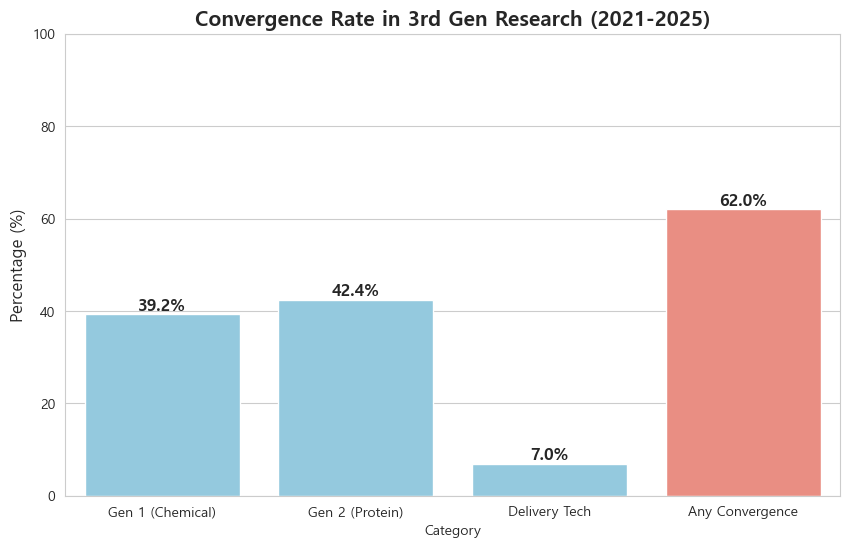

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_biomedical_20252021.xlsx'
df = pd.read_excel(file_path)

# 텍스트 통합 (Title + Abstract + Keywords)
cols = ['Title', 'Abstract', 'Keywords', 'NODE_TTLE', 'ABST_KR', 'ABST_EN']
text_cols = [c for c in cols if c in df.columns]
df['Full_Text'] = df[text_cols].fillna('').astype(str).agg(' '.join, axis=1).str.lower()

# Target-> 3세대 (유전자/세포)
gen3_keywords = ['gene', 'cell', 'mrna', 'rna', 'dna', 'crispr', 'car-t', 'stem cell']

# [Convergence Factors] 융합 요소
gen1_keywords = ['chemical', 'compound', 'drug', 'synthesis', 'lipid', 'polymer'] # 화학/합성
gen2_keywords = ['antibody', 'protein', 'peptide', 'enzyme', 'mab'] # 단백질/항체
tech_keywords = ['delivery', 'nano', 'vector', 'liposome', 'encapsulation', 'lnp'] # 전달기술


# Step 1: 3세대 관련 논문만 추출
df['Is_Gen3'] = df['Full_Text'].apply(lambda x: any(k in x for k in gen3_keywords))
df_gen3 = df[df['Is_Gen3']].copy()

# Step 2: 3세대 논문 내 타 기술 언급 여부 확인
df_gen3['Has_Gen1'] = df_gen3['Full_Text'].apply(lambda x: any(k in x for k in gen1_keywords))
df_gen3['Has_Gen2'] = df_gen3['Full_Text'].apply(lambda x: any(k in x for k in gen2_keywords))
df_gen3['Has_Tech'] = df_gen3['Full_Text'].apply(lambda x: any(k in x for k in tech_keywords))

# Step 3: 융합 비율 계산
total = len(df_gen3)
converged = df_gen3[(df_gen3['Has_Gen1']) | (df_gen3['Has_Gen2']) | (df_gen3['Has_Tech'])]
convergence_rate = len(converged) / total * 100

print(f" 분석 결과 요약 (n={total})")
print(f" - 1세대(화학) 융합: {df_gen3['Has_Gen1'].sum()}건 ({df_gen3['Has_Gen1'].mean()*100:.1f}%)")
print(f" - 2세대(항체) 융합: {df_gen3['Has_Gen2'].sum()}건 ({df_gen3['Has_Gen2'].mean()*100:.1f}%)")
print(f" - 전달기술(Tech) 융합: {df_gen3['Has_Tech'].sum()}건 ({df_gen3['Has_Tech'].mean()*100:.1f}%)")
print(f" [최종 결론] 3세대 융합 연구 비율: {convergence_rate:.1f}%")

results = pd.DataFrame({
    'Category': ['Gen 1 (Chemical)', 'Gen 2 (Protein)', 'Delivery Tech', 'Any Convergence'],
    'Value': [df_gen3['Has_Gen1'].mean()*100, df_gen3['Has_Gen2'].mean()*100, 
              df_gen3['Has_Tech'].mean()*100, convergence_rate]
})

plt.figure(figsize=(10, 6))
colors = ['skyblue', 'skyblue', 'skyblue', 'salmon']
ax = sns.barplot(data=results, x='Category', y='Value', palette=colors)

plt.title('Convergence Rate in 3rd Gen Research (2021-2025)', fontsize=15, fontweight='bold')
plt.ylabel('Percentage (%)', fontsize=12)
plt.ylim(0, 100)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width()/2., p.get_height()), 
                ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.show()

Graph saved as Network_Analysis_Result.png


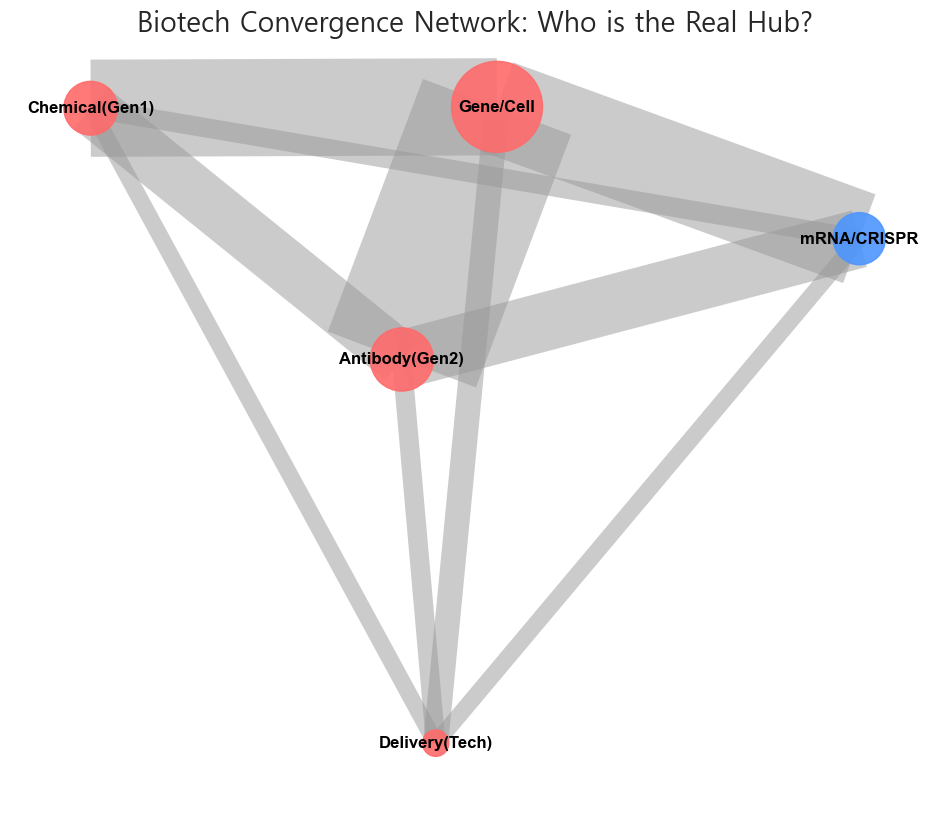

In [71]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from itertools import combinations

file_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_biomedical_20252021.xlsx'

df = pd.read_excel(file_path)

# 텍스트 통합
cols = ['Title', 'Abstract', 'Keywords', 'NODE_TTLE', 'ABST_KR', 'ABST_EN']
text_cols = [c for c in cols if c in df.columns]
df['Full_Text'] = df[text_cols].fillna('').astype(str).agg(' '.join, axis=1).str.lower()

#  키워드 정의 (노드)
# 구체적인 기술명으로 세분화
keywords = {
    # 3세대 (Target)
    'Gene/Cell': ['gene', 'cell', 'stem cell', 'car-t'],
    'mRNA/CRISPR': ['mrna', 'rna', 'crispr', 'cas9'],
    
    # 1,2세대 & 전달기술 (Hub 후보)
    'Antibody(Gen2)': ['antibody', 'mab', 'protein'],
    'Chemical(Gen1)': ['chemical', 'compound', 'drug'],
    'Delivery(Tech)': ['delivery', 'nanoparticle', 'lnp', 'vector', 'liposome']
}

# 역매핑 (키워드 -> 그룹)
keyword_map = {}
for group, keys in keywords.items():
    for k in keys:
        keyword_map[k] = group

# 엣지(Edge) 생성 - 동시 출현 계산
edges = {}
nodes_freq = {g: 0 for g in keywords.keys()}

for text in df['Full_Text']:
    found_groups = set()
    # 해당 논문에 등장한 그룹 찾기
    for group, keys in keywords.items():
        if any(k in text for k in keys):
            found_groups.add(group)
            nodes_freq[group] += 1
    
    # 그룹 간 연결 관계 카운트
    for g1, g2 in combinations(found_groups, 2):
        pair = tuple(sorted((g1, g2)))
        edges[pair] = edges.get(pair, 0) + 1

# 4. 네트워크 그래프 그리기
G = nx.Graph()

# 노드 추가 (크기는 빈도 비례)
for node, freq in nodes_freq.items():
    G.add_node(node, size=freq*50) # 사이즈 조절

# 엣지 추가 (두께는 동시출현 빈도 비례)
for (u, v), weight in edges.items():
    if weight > 0: # 연결된 것만
        G.add_edge(u, v, weight=weight)

# 시각화 설정
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, k=0.5, seed=42) # 레이아웃 고정

# 노드 색상 설정 (3세대는 파랑, 1/2세대는 빨강/주황)
node_colors = []
for node in G.nodes():
    if 'Gen' in node or 'Tech' in node:
        node_colors.append('#FF6B6B') # Hub (Red)
    else:
        node_colors.append('#4D96FF') # Spoke (Blue)

# 그리기
# 엣지
weights = [G[u][v]['weight']*2 for u,v in G.edges()]
nx.draw_networkx_edges(G, pos, width=weights, edge_color='#999999', alpha=0.5)

# 노드
sizes = [nodes_freq[node]*30 for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color=node_colors, alpha=0.9)

# 라벨?
nx.draw_networkx_labels(G, pos, font_size=12, font_family='sans-serif', font_weight='bold')

plt.title("Biotech Convergence Network: Who is the Real Hub?", fontsize=20)
plt.axis('off')

# 저장
plt.savefig('Network_Analysis_Result.png')
print("Graph saved as Network_Analysis_Result.png")

In [72]:
!pip install networkx

 그래프 저장: Final_Network_Graph.png


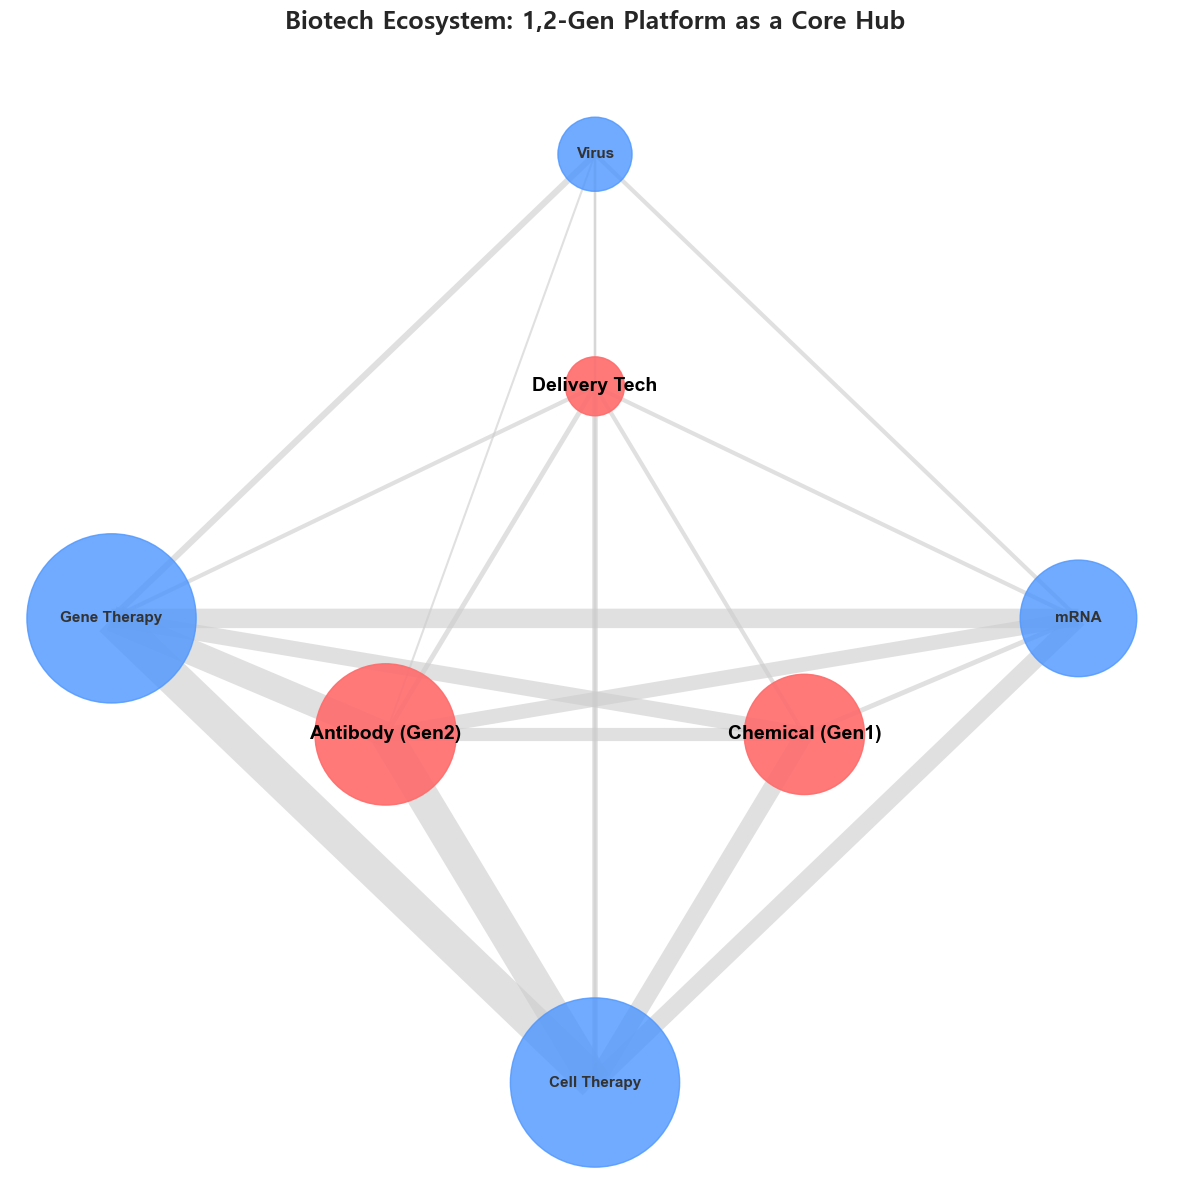

In [73]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. 데이터 로드
file_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_biomedical_20252021.xlsx'

df = pd.read_excel(file_path)

# 텍스트 통합
cols = ['Title', 'Abstract', 'Keywords', 'NODE_TTLE', 'ABST_KR', 'ABST_EN']
text_cols = [c for c in cols if c in df.columns]
df['Full_Text'] = df[text_cols].fillna('').astype(str).agg(' '.join, axis=1).str.lower()

# 2. 노드 정의 (Hub vs Spoke)
# Hub: 중심에 위치할 1,2세대 및 플랫폼 기술
hubs = {
    'Delivery Tech': ['delivery', 'nano', 'vector', 'liposome', 'lnp'],
    'Antibody (Gen2)': ['antibody', 'protein', 'mab'],
    'Chemical (Gen1)': ['chemical', 'compound', 'drug']
}

# Spoke: 주변을 도는 3세대 기술
spokes = {
    'Gene Therapy': ['gene', 'dna', 'genetic'],
    'Cell Therapy': ['cell', 'stem cell', 'car-t'],
    'mRNA': ['mrna', 'rna'],
    'CRISPR': ['crispr', 'cas9'],
    'Exosome': ['exosome'],
    'Virus': ['virus', 'viral']
}

# 3. 엣지 가중치 계산
nodes = {**hubs, **spokes}
edge_weights = {}
node_counts = {k: 0 for k in nodes.keys()}

for text in df['Full_Text']:
    found = [k for k, v in nodes.items() if any(kw in text for kw in v)]
    
    # 노드 빈도 카운트
    for k in found:
        node_counts[k] += 1
        
    # 동시 출현 엣지 카운트
    import itertools
    for u, v in itertools.combinations(found, 2):
        pair = tuple(sorted((u, v)))
        edge_weights[pair] = edge_weights.get(pair, 0) + 1

# 4. 그래프 생성
G = nx.Graph()

# 노드 추가 (빈도수 기반 크기 설정)
for node, count in node_counts.items():
    if count > 0: # 한 번이라도 나온 것만
        G.add_node(node, size=count)

# 엣지 추가 (최소 연결 강도 필터링)
for (u, v), w in edge_weights.items():
    if u in G.nodes and v in G.nodes and w >= 2: # 2번 이상 같이 나와야 연결
        G.add_edge(u, v, weight=w)

# 5. 레이아웃 설정 (Shell Layout)
# 리스트의 첫 번째 그룹(Hubs)을 중앙에, 두 번째 그룹(Spokes)을 바깥에 배치
hub_list = [n for n in G.nodes if n in hubs.keys()]
spoke_list = [n for n in G.nodes if n in spokes.keys()]

plt.figure(figsize=(12, 12), facecolor='white')
pos = nx.shell_layout(G, nlist=[hub_list, spoke_list])

# 시각화

# (1) 엣지 (연결선)
weights = [G[u][v]['weight'] for u, v in G.edges]
nx.draw_networkx_edges(G, pos, width=[w * 0.5 for w in weights], edge_color='#CCCCCC', alpha=0.6)

# (2) 노드 (점)
# Hub 노드 스타일
nx.draw_networkx_nodes(G, pos, nodelist=hub_list, 
                       node_size=[node_counts[n]*150 for n in hub_list], 
                       node_color='#FF6B6B', alpha=0.9, label='Hub (Platform)')
# Spoke 노드 스타일
nx.draw_networkx_nodes(G, pos, nodelist=spoke_list, 
                       node_size=[node_counts[n]*150 for n in spoke_list], 
                       node_color='#4D96FF', alpha=0.8, label='Spoke (Gen3)')

# (3) 라벨 (글자)
# Hub는 크게, Spoke는 작게
nx.draw_networkx_labels(G, pos, labels={n:n for n in hub_list}, font_size=14, font_weight='bold', font_color='black')
nx.draw_networkx_labels(G, pos, labels={n:n for n in spoke_list}, font_size=11, font_weight='bold', font_color='#333333')

# 마무리
plt.title("Biotech Ecosystem: 1,2-Gen Platform as a Core Hub", fontsize=18, fontweight='bold', pad=20)
plt.axis('off') # 축 숨기기
plt.tight_layout()

# 저장
plt.savefig('Final_Network_Graph.png', dpi=300)
print(" 그래프 저장: Final_Network_Graph.png")

 [연도별 3세대 융합 비율]
      count  sum  Rate
Year                  
2021     29   18  62.1
2022     34   16  47.1
2023     32   15  46.9
2024     29   18  62.1
2025     32   25  78.1


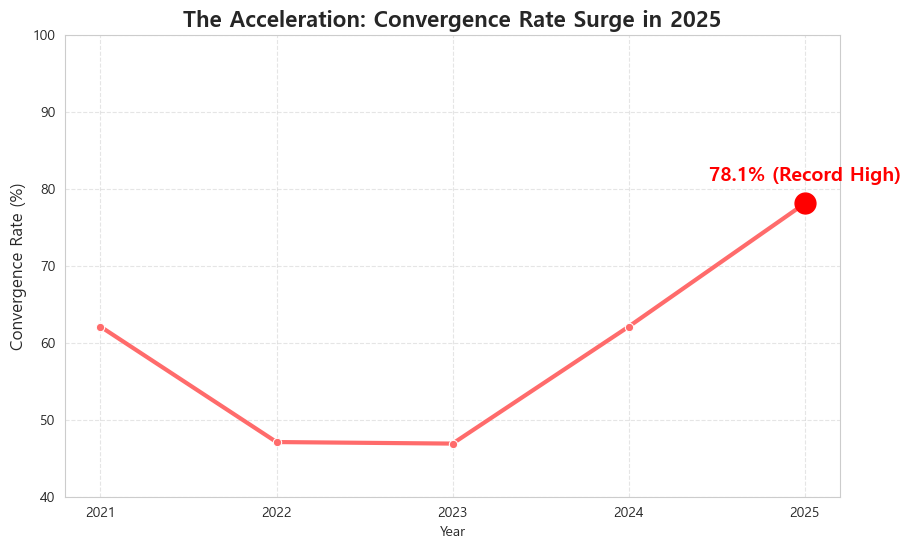


 Top 5
('cell', 'protein'): 44회
('gene', 'protein'): 28회
('rna', 'protein'): 19회
('cell', 'drug'): 17회
('gene', 'polymer'): 10회


In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 로드 (DBpia New Data)
file_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_biomedical_20252021.xlsx'
df = pd.read_excel(file_path)

# 텍스트 통합 및 연도 필터링
cols = ['Title', 'Abstract', 'Keywords', 'NODE_TTLE']
text_cols = [c for c in cols if c in df.columns]
df['Full_Text'] = df[text_cols].fillna('').astype(str).agg(' '.join, axis=1).str.lower()
df['Year'] = df['Year·Month'].astype(str).str[:4] # 연도 추출
df = df[df['Year'].isin(['2021', '2022', '2023', '2024', '2025'])]

# 2. 키워드 정의
gen3_keywords = ['gene', 'cell', 'mrna', 'rna', 'crispr', 'cas9'] # 3세대
support_keywords = [
    'chemical', 'drug', 'polymer', 'lipid',  # 1세대 (소재/화학)
    'antibody', 'protein', 'enzyme',         # 2세대 (단백질)
    'delivery', 'nano', 'vector', 'lnp'      # 전달 기술
]

# 3. 융합 추이 분석 (Time-Series)
# 3세대 논문 추출
df_gen3 = df[df['Full_Text'].apply(lambda x: any(k in x for k in gen3_keywords))].copy()

# 융합 여부 판별 (3세대 논문에 Support 키워드가 있는지?)
df_gen3['Is_Converged'] = df_gen3['Full_Text'].apply(lambda x: any(k in x for k in support_keywords))

# 연도별 통계 계산
yearly_stats = df_gen3.groupby('Year')['Is_Converged'].agg(['count', 'sum'])
yearly_stats['Rate'] = (yearly_stats['sum'] / yearly_stats['count'] * 100).round(1)

print(" [연도별 3세대 융합 비율]")
print(yearly_stats)

# 4. 시각화 (Trend Graph)
plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly_stats, x='Year', y='Rate', marker='o', linewidth=3, color='#FF6B6B')

# 2025년 강조 (Red Dot)
rate_2025 = yearly_stats.loc['2025', 'Rate']
plt.plot(4, rate_2025, 'o', markersize=15, color='red')
plt.text(4, rate_2025 + 3, f"{rate_2025}% (Record High)", 
         ha='center', fontsize=14, fontweight='bold', color='red')

plt.title('The Acceleration: Convergence Rate Surge in 2025', fontsize=16, fontweight='bold')
plt.ylabel('Convergence Rate (%)', fontsize=12)
plt.ylim(40, 100)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 5. 핵심 조합(Top Pairs) 추출
pair_counts = {}
for text in df_gen3['Full_Text']:
    present_g3 = [k for k in gen3_keywords if k in text]
    present_sup = [k for k in support_keywords if k in text]
    
    for g3 in present_g3:
        for sup in present_sup:
            pair = (g3, sup)
            pair_counts[pair] = pair_counts.get(pair, 0) + 1

print("\n Top 5")
for pair, count in sorted(pair_counts.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"{pair}: {count}회")

 [연도별 3세대 융합 비율 (Strict Mode)]
      count  sum  Rate
Year                  
2021      2    1  50.0
2022      3    1  33.3
2023      7    1  14.3
2024      3    0   0.0
2025      5    2  40.0


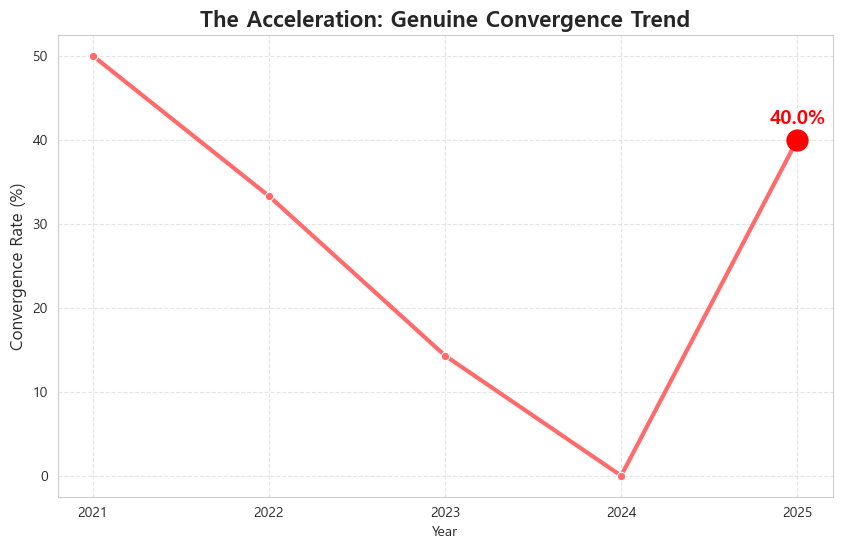


 top5
('stem cell', 'delivery'): 2회
('mrna', 'vector'): 2회
('mrna', 'delivery'): 2회
('mrna', 'nano'): 2회
('stem cell', 'liposome'): 1회


In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 로드
file_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_biomedical_20252021.xlsx'
df = pd.read_excel(file_path)

# 텍스트 통합 및 연도 필터링
cols = ['Title', 'Abstract', 'Keywords', 'NODE_TTLE']
text_cols = [c for c in cols if c in df.columns]
df['Full_Text'] = df[text_cols].fillna('').astype(str).agg(' '.join, axis=1).str.lower()
df['Year'] = df['Year·Month'].astype(str).str[:4]
df = df[df['Year'].isin(['2021', '2022', '2023', '2024', '2025'])]

# 키워드 엄격화
# --> 너무 흔한 단어(cell, gene, drug, protein)는 제외하고 구체적인 기술명만 사용하자

gen3_keywords = [
    'gene therap', 'cell therap', 'stem cell', # 단순 cell/gene 제외 -> therapy만
    'mrna', 'crispr', 'cas9', 'car-t', 'oligonucleotide', 'exosome'
]

support_keywords = [
    'delivery', 'nano', 'vector', 'lnp', 'liposome', 'encapsulation', # 전달 기술 집중
    'antibody', 'mab', 'conjugate' # 항체/접합 (단순 protein 제외)
]
# ==============================================================================

# 3. 융합 추이 분석
df_gen3 = df[df['Full_Text'].apply(lambda x: any(k in x for k in gen3_keywords))].copy()
df_gen3['Is_Converged'] = df_gen3['Full_Text'].apply(lambda x: any(k in x for k in support_keywords))

# 연도별 통계
yearly_stats = df_gen3.groupby('Year')['Is_Converged'].agg(['count', 'sum'])
yearly_stats['Rate'] = (yearly_stats['sum'] / yearly_stats['count'] * 100).round(1)

print(" [연도별 3세대 융합 비율 (Strict Mode)]")
print(yearly_stats)

# 4. 시각화
plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly_stats, x='Year', y='Rate', marker='o', linewidth=3, color='#FF6B6B')

# 2025년 포인트 강조
if '2025' in yearly_stats.index:
    rate_2025 = yearly_stats.loc['2025', 'Rate']
    plt.plot(4, rate_2025, 'o', markersize=15, color='red')
    plt.text(4, rate_2025 + 2, f"{rate_2025}%", ha='center', fontsize=14, fontweight='bold', color='red')

plt.title('The Acceleration: Genuine Convergence Trend', fontsize=16, fontweight='bold')
plt.ylabel('Convergence Rate (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 5. 핵심 조합 확인
pair_counts = {}
for text in df_gen3['Full_Text']:
    present_g3 = [k for k in gen3_keywords if k in text]
    present_sup = [k for k in support_keywords if k in text]
    for g3 in present_g3:
        for sup in present_sup:
            pair = (g3, sup)
            pair_counts[pair] = pair_counts.get(pair, 0) + 1

print("\n top5")
for pair, count in sorted(pair_counts.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"{pair}: {count}회")

 데이터 분석 및 시각화 생성 중...


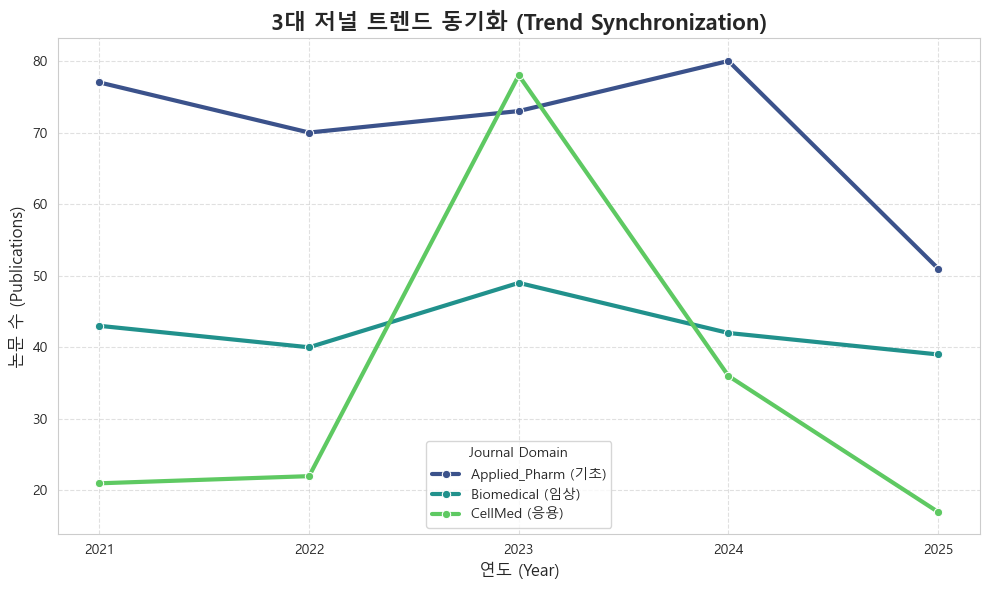

C:\Users\jacob\AppData\Local\Temp\ipykernel_30676\2213896419.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=authors_df, y='Researcher', x='Publications', palette='rocket')


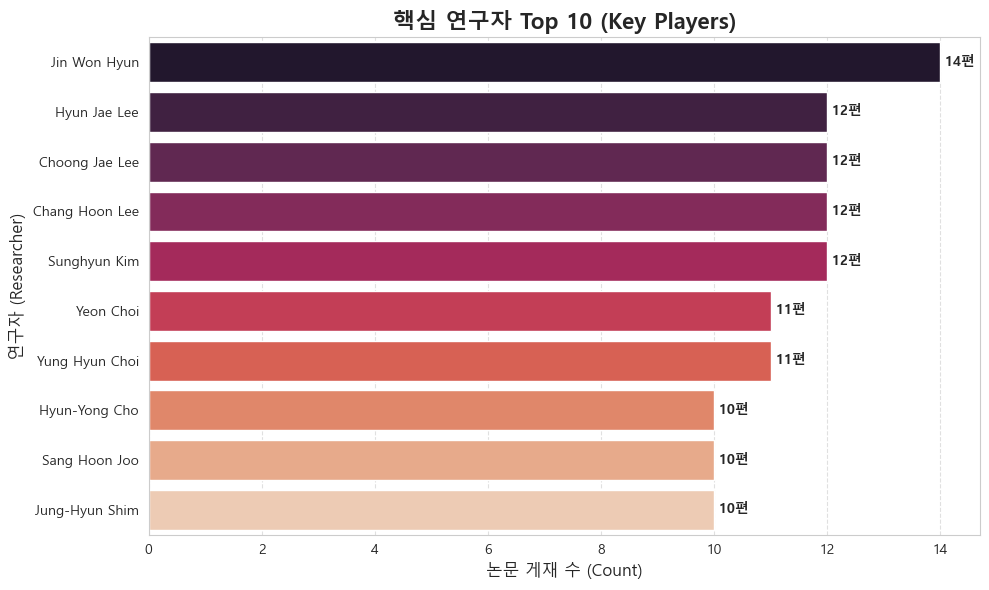

C:\Users\jacob\AppData\Local\Temp\ipykernel_30676\2213896419.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=keywords_df, y='Keyword', x='Frequency', palette='mako')


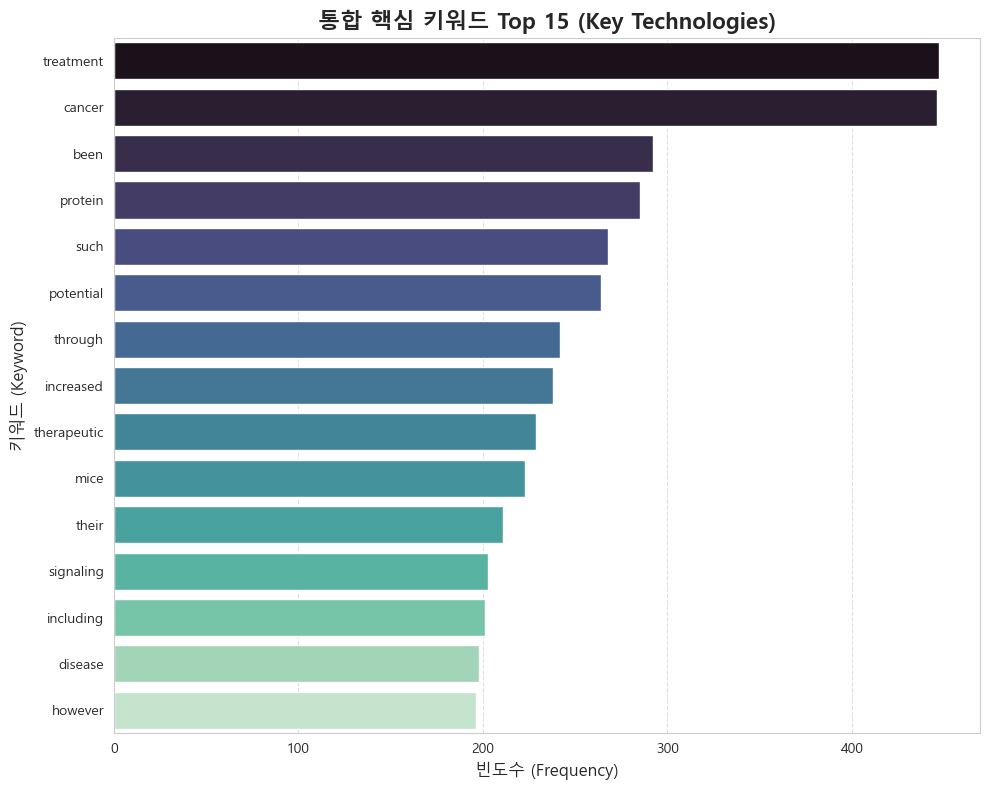

In [76]:
import pandas as pd
import collections
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager, rc
import platform


if platform.system() == 'Windows':
    font_name = font_manager.FontProperties(fname="c:/Windows/Fonts/malgun.ttf").get_name()
    rc('font', family=font_name)
elif platform.system() == 'Darwin': # Mac
    rc('font', family='AppleGothic')
else:
    rc('font', family='NanumGothic')

plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지


files = {
    "CellMed (응용)": r"C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_cellmed_20252021.xlsx - first.csv",
    "Applied_Pharm (기초)": r"C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_kdrug_20252021.xlsx - first.csv",
    "Biomedical (임상)": r"C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_biomedical_20252021.xlsx - first.csv"
}


def process_author_name(name_str):
    name_str = str(name_str).strip()
    if ',' in name_str: # "Kim, Cheol-Su" -> "Cheol-Su Kim"
        parts = name_str.split(',')
        if len(parts) >= 2:
            return f"{parts[1].strip()} {parts[0].strip()}"
    return name_str

all_dfs = []
all_authors = []

print(" 데이터 분석 및 시각화 생성 중...")

for journal_name, file_path in files.items():
    # 경로 보정 (xlsx/csv 혼용 대응)
    if not os.path.exists(file_path):
        alt_path = file_path.replace(" - first.csv", "")
        if os.path.exists(alt_path):
            file_path = alt_path
        else:
            print(f" 파일 없음: {file_path}")
            continue

    try:
        # 파일 읽기
        try:
            df = pd.read_excel(file_path)
        except:
            try:
                df = pd.read_csv(file_path, encoding='utf-8-sig')
            except:
                df = pd.read_csv(file_path, encoding='cp949')

        df.columns = [str(c).strip() for c in df.columns]
        
        # 컬럼 매핑
        year_col = next((c for c in df.columns if 'Year' in c or '년' in c), None)
        author_col = next((c for c in df.columns if 'Author' in c or '저자' in c), None)
        abstract_col = next((c for c in df.columns if 'Abstract' in c or '초록' in c), None)

        if year_col and author_col:
            # 연도 정제
            df['Year_Clean'] = df[year_col].astype(str).apply(lambda x: x.split('.')[0] if '.' in x else x)
            df = df[df['Year_Clean'].isin(['2021', '2022', '2023', '2024', '2025'])]
            df['Journal_Type'] = journal_name
            all_dfs.append(df)
            
            # 저자 정제
            for authors_str in df[author_col].dropna().astype(str):
                for auth in authors_str.split(';'):
                    full_name = process_author_name(auth)
                    if len(full_name) > 1 and not full_name.isdigit():
                        all_authors.append(full_name)
                        
    except Exception as e:
        print(f"Error: {e}")

if not all_dfs:
    print("데이터 로드 실패. 경로를 확인하세요.")
    exit()

merged_df = pd.concat(all_dfs, ignore_index=True)


trend_data = merged_df.groupby(['Year_Clean', 'Journal_Type']).size().reset_index(name='Count')

plt.figure(figsize=(10, 6))
sns.lineplot(data=trend_data, x='Year_Clean', y='Count', hue='Journal_Type', 
             marker='o', linewidth=3, palette='viridis')

plt.title('3대 저널 트렌드 동기화 (Trend Synchronization)', fontsize=16, fontweight='bold')
plt.xlabel('연도 (Year)', fontsize=12)
plt.ylabel('논문 수 (Publications)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Journal Domain')
plt.tight_layout()
plt.show() # 첫 번째 그래프 출력

top_authors_counts = collections.Counter(all_authors).most_common(10)
authors_df = pd.DataFrame(top_authors_counts, columns=['Researcher', 'Publications'])

plt.figure(figsize=(10, 6))
sns.barplot(data=authors_df, y='Researcher', x='Publications', palette='rocket')

plt.title('핵심 연구자 Top 10 (Key Players)', fontsize=16, fontweight='bold')
plt.xlabel('논문 게재 수 (Count)', fontsize=12)
plt.ylabel('연구자 (Researcher)', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
for index, value in enumerate(authors_df['Publications']):
    plt.text(value, index, f' {value}편', va='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show() # 두 번째 그래프 출력


text = " ".join(merged_df['Abstract'].dropna().astype(str).tolist()).lower()
text = re.sub(r'[^a-z\s]', '', text)
stopwords = set(['the', 'and', 'of', 'in', 'to', 'a', 'with', 'for', 'is', 'was', 'were', 'by', 'as', 'on', 'at', 'that', 'this', 'are', 'from', 'be', 'an', 'or', 'which', 'study', 'using', 'results', 'method', 'conclusion', 'background', 'aim', 'methods', 'significant', 'significantly', 'group', 'compared', 'expression', 'cells', 'cell', 'control', 'levels', 'effect', 'effects', 'used', 'have', 'these', 'analysis', 'high', 'also', 'human', 'after', 'various', 'between', 'during', 'showed', 'activity'])
words = [w for w in text.split() if w not in stopwords and len(w) > 3]

top_keywords = collections.Counter(words).most_common(15)
keywords_df = pd.DataFrame(top_keywords, columns=['Keyword', 'Frequency'])

plt.figure(figsize=(10, 8))
sns.barplot(data=keywords_df, y='Keyword', x='Frequency', palette='mako')

plt.title('통합 핵심 키워드 Top 15 (Key Technologies)', fontsize=16, fontweight='bold')
plt.xlabel('빈도수 (Frequency)', fontsize=12)
plt.ylabel('키워드 (Keyword)', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show() # 세 번째 그래프 출력

In [77]:
import pandas as pd

file_paths = {
    'K-Drug (약물학)': r'C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_kdrug_20252021.xlsx',
    'CellMed (세포의학)': r'C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_cellmed_20252021.xlsx'
}
gen3_keywords = [
    'gene therap', 'cell therap', 'stem cell', 
    'mrna', 'crispr', 'cas9', 'car-t', 'oligonucleotide', 'exosome'
]

support_keywords = [
    'delivery', 'nano', 'vector', 'lnp', 'liposome', 'encapsulation', # 전달체
    'antibody', 'mab', 'conjugate' # 항체/접합 기술
]

for name, path in file_paths.items():
    print(f"\n{'='*10} {name} 분석 결과 {'='*10}")
    
    try:
        # 엑셀 파일 읽기
        df = pd.read_excel(path)
        
        # 텍스트 통합 (제목 + 초록 + 키워드)
        cols = ['Title', 'Abstract', 'Keywords', 'NODE_TTLE']
        text_cols = [c for c in cols if c in df.columns]
        df['Full_Text'] = df[text_cols].fillna('').astype(str).agg(' '.join, axis=1).str.lower()
        
        # 연도 추출 (2021~2025 필터링)
        if 'Year·Month' in df.columns:
            df['Year'] = df['Year·Month'].astype(str).str[:4]
        else:
            df['Year'] = df['Year'].astype(str).str[:4] # 컬럼명이 다를 경우 대비
            
        df = df[df['Year'].isin(['2021', '2022', '2023', '2024', '2025'])]

        df_gen3 = df[df['Full_Text'].apply(lambda x: any(k in x for k in gen3_keywords))].copy()
        
        if len(df_gen3) == 0:
            print("  -> 3세대 관련 논문이 없습니다.")
            continue

        df_gen3['Is_Converged'] = df_gen3['Full_Text'].apply(lambda x: any(k in x for k in support_keywords))
        
        stats = df_gen3.groupby('Year')['Is_Converged'].agg(['count', 'sum'])
        stats.columns = ['Total_Gen3', 'Converged_Count'] # 컬럼명 변경
        stats['Rate(%)'] = (stats['Converged_Count'] / stats['Total_Gen3'] * 100).round(1)
        
        print(stats)

        df_2025 = df_gen3[(df_gen3['Year'] == '2025') & (df_gen3['Is_Converged'])]
        
        pair_counts = {}
        for text in df_2025['Full_Text']:
            present_g3 = [k for k in gen3_keywords if k in text]
            present_sup = [k for k in support_keywords if k in text]
            
            for g3 in present_g3:
                for sup in present_sup:
                    pair = (g3, sup)
                    pair_counts[pair] = pair_counts.get(pair, 0) + 1
        
        if pair_counts:
            print("\n  2025년 주요 융합 조합 (Top 3):")
            sorted_pairs = sorted(pair_counts.items(), key=lambda x: x[1], reverse=True)[:3]
            for pair, count in sorted_pairs:
                print(f"   - {pair}: {count}회")
        else:
            print("\n  (2025년 융합 논문에서 특정 키워드 조합이 발견되지 않음)")

    except Exception as e:
        print(f"  [Error] 파일을 읽는 중 오류 발생: {e}")


========== K-Drug (약물학) 분석 결과 ==========
      Total_Gen3  Converged_Count  Rate(%)
Year                                      
2021           9                0      0.0
2022          12                2     16.7
2023          12                1      8.3
2024          12                0      0.0
2025          10                3     30.0

  2025년 주요 융합 조합 (Top 3):
   - ('mrna', 'delivery'): 2회
   - ('mrna', 'conjugate'): 1회
   - ('stem cell', 'nano'): 1회

========== CellMed (세포의학) 분석 결과 ==========
      Total_Gen3  Converged_Count  Rate(%)
Year                                      
2023           1                0      0.0
2025           3                1     33.3

  2025년 주요 융합 조합 (Top 3):
   - ('mrna', 'delivery'): 1회
   - ('mrna', 'nano'): 1회
   - ('mrna', 'liposome'): 1회


=== [표] K-Drug 연도별 데이터 ===
      Total Papers (Bar)  Converged (Line)  Rate (%)
Year                                                
2021                   9                 0       0.0
2022                  12                 2      16.7
2023                  11                 0       0.0
2024                  12                 0       0.0
2025                  10                 2      20.0


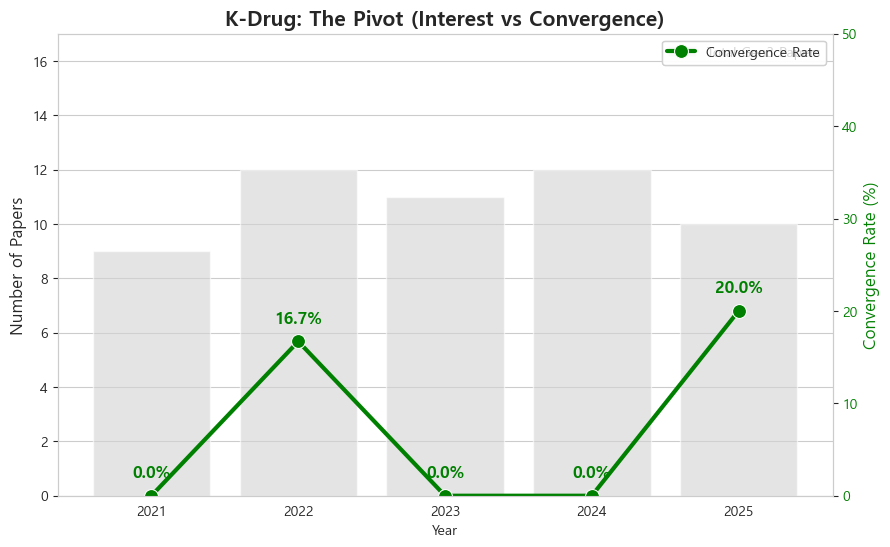

In [78]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------------------------------------------------------
# 1. 한글 폰트 설정
# -----------------------------------------------------------------------------
plt.rcParams['font.family'] = 'Malgun Gothic' # Windows
plt.rcParams['axes.unicode_minus'] = False

# -----------------------------------------------------------------------------
# 2. 데이터 로드 및 전처리 (K-Drug)
# -----------------------------------------------------------------------------
file_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_kdrug_20252021.xlsx'

try:
    df = pd.read_excel(file_path)
except:
    df = pd.read_csv(file_path) # csv일 경우 대비

# 텍스트 통합
cols = ['Title', 'Abstract', 'Keywords', 'NODE_TTLE']
text_cols = [c for c in cols if c in df.columns]
df['Full_Text'] = df[text_cols].fillna('').astype(str).agg(' '.join, axis=1).str.lower()

# 연도 추출
if 'Year·Month' in df.columns:
    df['Year'] = df['Year·Month'].astype(str).str[:4]
else:
    df['Year'] = df['Year'].astype(str).str[:4]

# 2021~2025 필터링
df = df[df['Year'].isin(['2021', '2022', '2023', '2024', '2025'])].copy()

# -----------------------------------------------------------------------------
# 3. 엄격한 필터링 (Strict Mode)
# -----------------------------------------------------------------------------
gen3_keys = ['gene therap', 'cell therap', 'stem cell', 'mrna', 'crispr', 'car-t']
sup_keys = ['delivery', 'lnp', 'vector', 'nanoparticle', 'conjugate', 'antibody']

# (1) 분모: 3세대 관련 논문 전체 수
df_gen3 = df[df['Full_Text'].apply(lambda x: any(k in x for k in gen3_keys))].copy()

# (2) 분자: 그중 융합된 논문 수
df_gen3['Is_Converged'] = df_gen3['Full_Text'].apply(lambda x: any(k in x for k in sup_keys))

# (3) 연도별 집계 (표 만들기)
stats = df_gen3.groupby('Year')['Is_Converged'].agg(['count', 'sum'])
stats.columns = ['Total Papers (Bar)', 'Converged (Line)']
stats['Rate (%)'] = (stats['Converged (Line)'] / stats['Total Papers (Bar)'] * 100).round(1)

print("=== [표] K-Drug 연도별 데이터 ===")
print(stats)

# -----------------------------------------------------------------------------
# 4. 콤보 차트 시각화 (Bar + Line)
# -----------------------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(10, 6))

# 막대 그래프 (전체 논문 수 - 관심도)
sns.barplot(x=stats.index, y=stats['Total Papers (Bar)'], ax=ax1, color='lightgray', alpha=0.6, label='Total Gen3 Papers')
ax1.set_ylabel('Number of Papers', fontsize=12)
ax1.set_ylim(0, max(stats['Total Papers (Bar)']) + 5)

# 꺾은선 그래프 (융합 비율 - 질적 변화)
ax2 = ax1.twinx()
sns.lineplot(x=stats.index, y=stats['Rate (%)'], ax=ax2, color='green', marker='o', linewidth=3, markersize=10, label='Convergence Rate')
ax2.set_ylabel('Convergence Rate (%)', fontsize=12, color='green')
ax2.set_ylim(0, 50)
ax2.tick_params(axis='y', labelcolor='green')

# 값 표시 (Annotation)
for i, rate in enumerate(stats['Rate (%)']):
    ax2.text(i, rate + 2, f"{rate}%", color='green', ha='center', fontweight='bold', fontsize=12)

# 제목 및 저장
plt.title('K-Drug: The Pivot (Interest vs Convergence)', fontsize=15, fontweight='bold')
plt.grid(False)
plt.savefig('k_drug_analysis.png', dpi=300)
plt.show()

=== [표] CellMed 연도별 데이터 ===
      Total Papers  Converged  Rate (%)
Year                                   
2023             1          0       0.0
2025             3          1      33.3


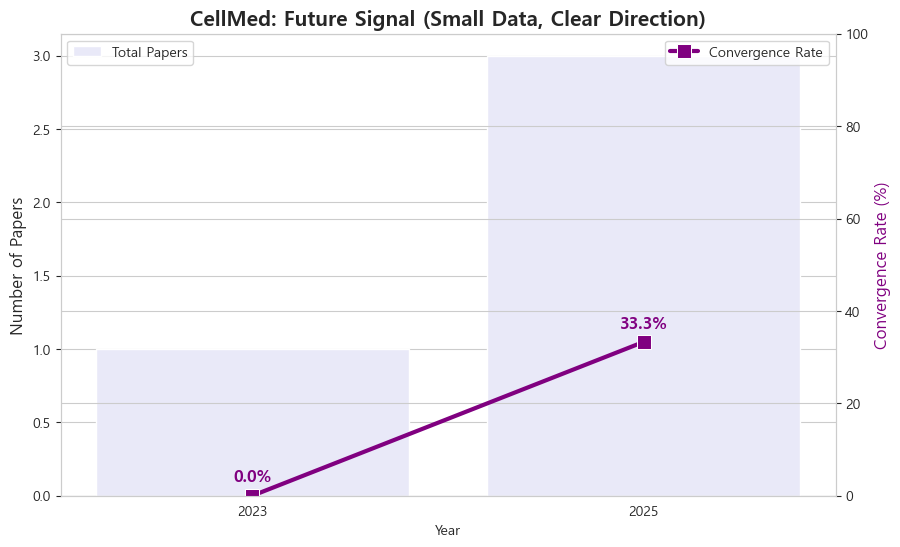

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

file_path = r'C:\Users\jacob\Desktop\ssu_Datathon\data\dbpia_metadata_cellmed_20252021.xlsx'

try:
    df = pd.read_excel(file_path)
except:
    df = pd.read_csv(file_path)

# 전처리
cols = ['Title', 'Abstract', 'Keywords', 'NODE_TTLE']
text_cols = [c for c in cols if c in df.columns]
df['Full_Text'] = df[text_cols].fillna('').astype(str).agg(' '.join, axis=1).str.lower()

if 'Year·Month' in df.columns:
    df['Year'] = df['Year·Month'].astype(str).str[:4]
else:
    df['Year'] = df['Year'].astype(str).str[:4]

df = df[df['Year'].isin(['2021', '2022', '2023', '2024', '2025'])].copy()


gen3_keys = ['gene therap', 'cell therap', 'stem cell', 'mrna', 'crispr', 'exosome']
sup_keys = ['delivery', 'lnp', 'liposome', 'nano', 'vector']

# 집계
df_gen3 = df[df['Full_Text'].apply(lambda x: any(k in x for k in gen3_keys))].copy()
df_gen3['Is_Converged'] = df_gen3['Full_Text'].apply(lambda x: any(k in x for k in sup_keys))

stats = df_gen3.groupby('Year')['Is_Converged'].agg(['count', 'sum'])
stats.columns = ['Total Papers', 'Converged']
stats['Rate (%)'] = (stats['Converged'] / stats['Total Papers'] * 100).round(1)

print("=== [표] CellMed 연도별 데이터 ===")
print(stats)

fig, ax1 = plt.subplots(figsize=(10, 6))

# 막대 (데이터 규모)
sns.barplot(x=stats.index, y=stats['Total Papers'], ax=ax1, color='lavender', label='Total Papers')
ax1.set_ylabel('Number of Papers', fontsize=12)

# 꺾은선 (미래 방향성)
ax2 = ax1.twinx()
sns.lineplot(x=stats.index, y=stats['Rate (%)'], ax=ax2, color='purple', marker='s', linewidth=3, markersize=10, label='Convergence Rate')
ax2.set_ylabel('Convergence Rate (%)', fontsize=12, color='purple')
ax2.set_ylim(0, 100) # 비율이 높을 수 있으므로 100까지

# 값 표시
for i, rate in enumerate(stats['Rate (%)']):
    ax2.text(i, rate + 3, f"{rate}%", color='purple', ha='center', fontweight='bold', fontsize=12)

plt.title('CellMed: Future Signal (Small Data, Clear Direction)', fontsize=15, fontweight='bold')
plt.savefig('cellmed_analysis.png', dpi=300)
plt.show()